## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Marin Marcillac

**Date:** 10/12/2026

In [11]:
import numpy as np
import pandas as pd
def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

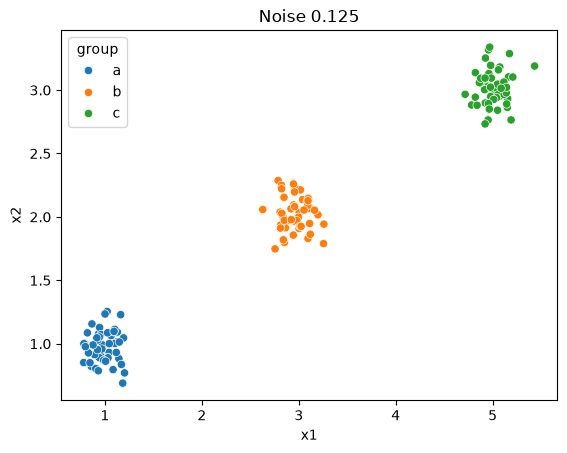

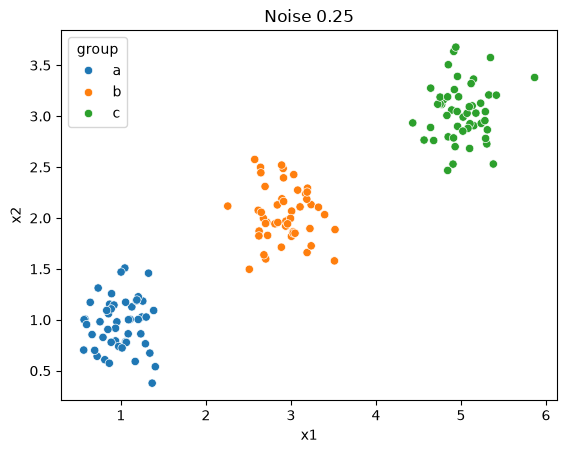

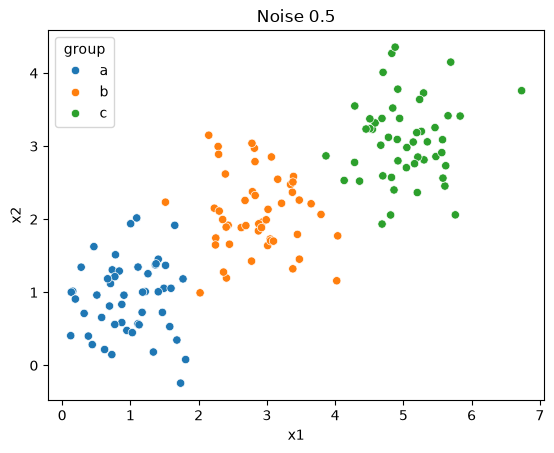

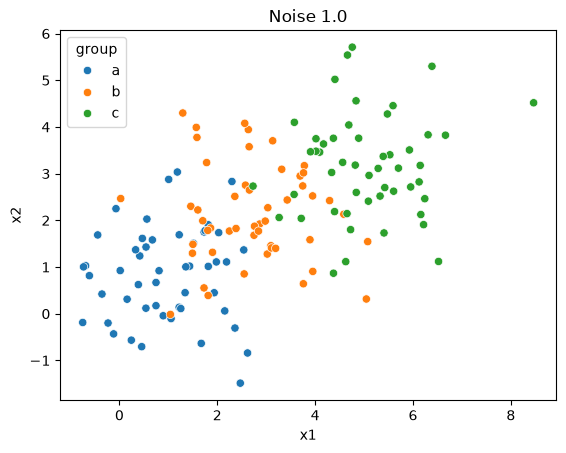

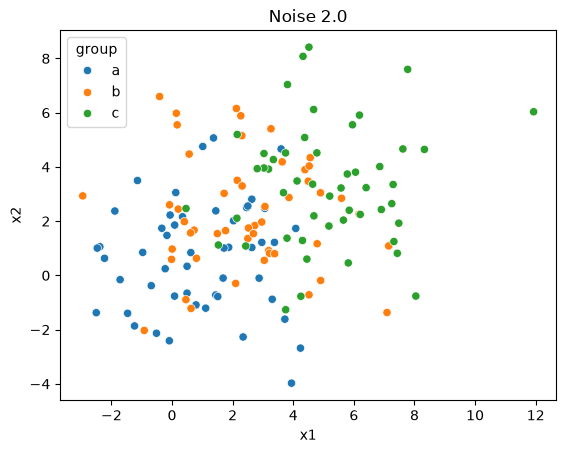

In [12]:
import seaborn as sns 
import matplotlib.pyplot as plt


sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group").set(title="Noise 0.125")
plt.show()
sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group").set(title="Noise 0.25")
plt.show()
sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group").set(title="Noise 0.5")
plt.show()
sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group").set(title="Noise 1.0")
plt.show()
sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group").set(title="Noise 2.0")
plt.show()

Question 1: As the noise increases from 0.125 to 2.0, the cluster spread out and increasignly overlap each other. At a noise level of 0.125, there are three perfectly distict, tightly packed clusters. As the noise increases to 0.5, the edjetives the clusters begin to touch each other. By the time thae noise reaches 2.0, the points are scattered that there is no telling what the distict groups are becuase it looks like a big clouds. 

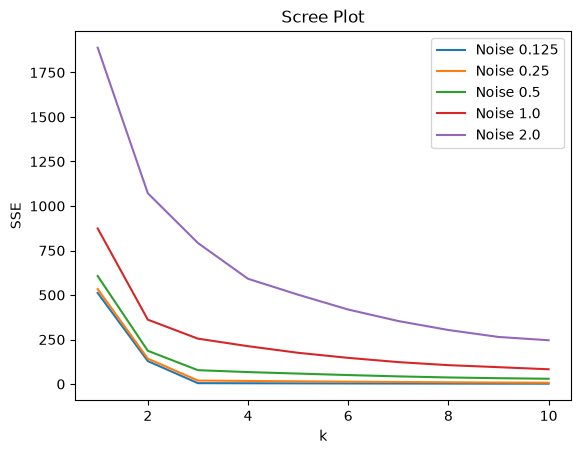

In [13]:

#my loop wasnt working and dont know why so I just used this hopefully Ai can help and make me the right loop
from sklearn.cluster import KMeans
ks = np.arange(1, 11)

SSE_0_125 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(df0_125[["x1", "x2"]]).inertia_ for k in ks]
SSE_0_25 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(df0_25[["x1", "x2"]]).inertia_ for k in ks]
SSE_0_5 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(df0_5[["x1", "x2"]]).inertia_ for k in ks]
SSE_1_0 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(df1_0[["x1", "x2"]]).inertia_ for k in ks]
SSE_2_0 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(df2_0[["x1", "x2"]]).inertia_ for k in ks]


sns.lineplot(x=ks, y=SSE_0_125, label="Noise 0.125")
sns.lineplot(x=ks, y=SSE_0_25, label="Noise 0.25")
sns.lineplot(x=ks, y=SSE_0_5, label="Noise 0.5")
sns.lineplot(x=ks, y=SSE_1_0, label="Noise 1.0")
sns.lineplot(x=ks, y=SSE_2_0, label="Noise 2.0").set(title="Scree Plot", xlabel="k", ylabel="SSE")

plt.show()

In [ ]:
#Increasing the noise level affects the scree plot in two ways. There is a higher overall error in in which the sse curve is signifally higher because the points are farther away from their cluster centers. 
#At low noise levels there is a sharp distict elbow at k=3 so it make it easy to choose the correct number of cluster. 
#When the nouse increases to 1.0 and 2,0, the sharp bend becomes more gradual and with high noise, 
#the SSE decreases without super big endges so it makes it extremly difficult to confiednelty select the right k value.
#SSE measures are tightly packed the cluster are. 

In [1]:
 

#The elbow helps us figure out the best k value by showing exactly where the algorithm stops finding real groups and starts just fitting random noise. 
#For the low noise datasets, the algorithm easily spots the three distinct clumps. 
#Moving from k=1 to k=2 and then to k=3 causes steep drops in the SSE because the algorithm is successfully identifying those separate groups. 
#However, once k goes above 3, the line suddenly flattens out.. With the high noise datasets,
#those distinct clumps have basically merged into one giant cloud.
#Because the noise is so high, increasing k just randomly slices up this massive blob without actually separating real groups. Since it never locks onto clear clusters, 
#the SSE just drops at a slow, steady rate and we never get that clear "elbow" shape.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans


In [3]:
df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
df_2020 = df.loc[df["Year"] == 2020].dropna().copy()
print("Number of countries")
print(len(df_2020))
#Answer:Yes, further cleaning should be done. I did get 148 countries, but there are probably 
#extreme outliers (like the United States) that will skew the results because we are using max-min normalization.

Number of countries
148


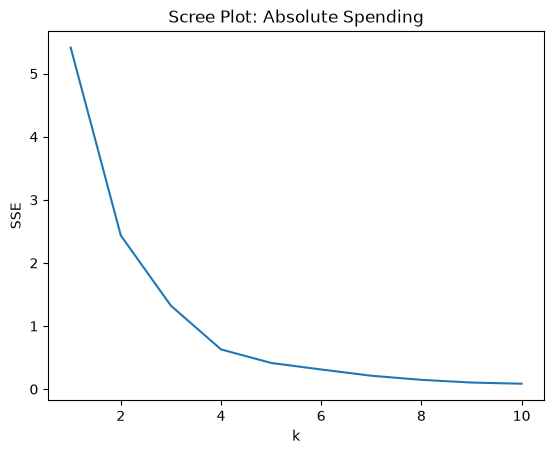

In [4]:
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df_2020.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X2 = (unscaled - mins) / ranges

ks = np.arange(1, 11)
SSE2 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X2).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE2).set(title="Scree Plot: Absolute Spending", xlabel="k", ylabel="SSE")
plt.show()

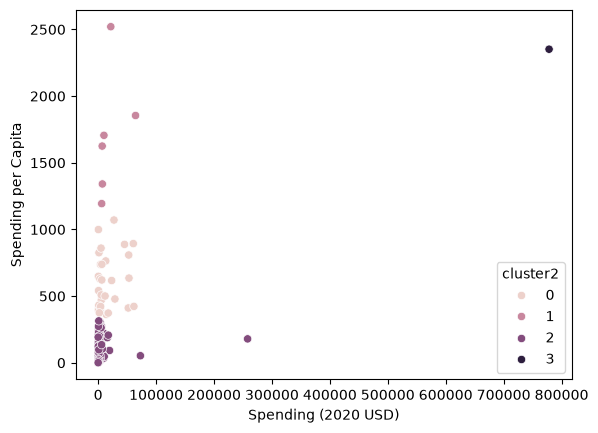

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster2                                                                   
0                       30.0   17077.591354  20583.053357     405.790494   
1                        6.0   19443.362047  22861.507114    6095.708713   
2                      111.0    4859.185065  25405.739131       8.622460   
3                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster2                                                               
0           2294.039665    5857.060906   26296.001003   61712.537169   
1           7023.251766    8624.225729   18857.070183   64558.400000   
2            130.010211     382.464677    2297.032353  257973.429834   
3         778397.200000  778397.200

In [6]:
model2 = KMeans(n_clusters=4, n_init="auto", random_state=0).fit(X2)
df_2020["cluster2"] = model2.labels_
sns.scatterplot(data=df_2020, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster2")
plt.show()
print(df_2020.groupby("cluster2")[features].describe())

In [ ]:
#Looking at the describe table, I see that the algorithm split the data into one massive group,
#two middle groups, and one extreme outlier. The United States is in Cluster 3 entirely by itself. 
#I can tell because the count for that cluster is exactly 1, and the absolute spending is $778 billion. 
#The main pattern I notice is that cluster is driven by extreme differences in wealth and country size. 
#The  majority of the world (111 countries) gets lumped together into a single low-spending group, while the country like US is so large that the algorithm is forced to isolate it.


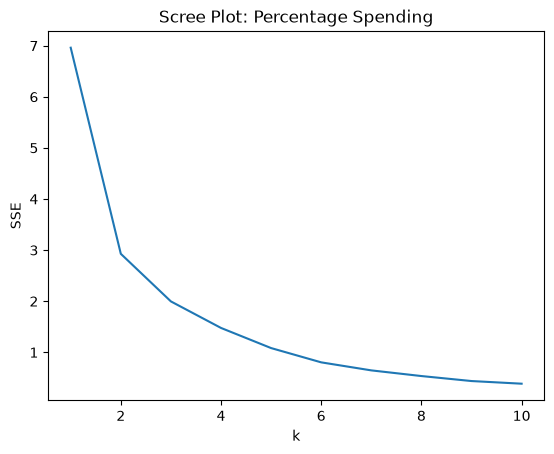

In [8]:
features3 = ["Percent of Government Spending", "Percent of GDP"]
unscaled3 = df_2020.loc[:, features3]
mins3 = unscaled3.min()
ranges3 = unscaled3.max() - mins3
X3 = (unscaled3 - mins3) / ranges3

SSE3 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X3).inertia_ 
    for k in ks
]
sns.lineplot(x=ks, y=SSE3).set(title="Scree Plot: Percentage Spending", xlabel="k", ylabel="SSE")
plt.show()


#For the percentage variables, I chose k=3 based on the elbow of my scree plot. The clusters are more balanced. 
#Because percentages normalize for a country's size and total wealth, the algorithm stops grouping countries by economic dominance. 
#Instead, it groups them by how heavily they prioritize the military. 
#This means smaller but highly militarized nations form the top clusters, rather than just the the superpowers.


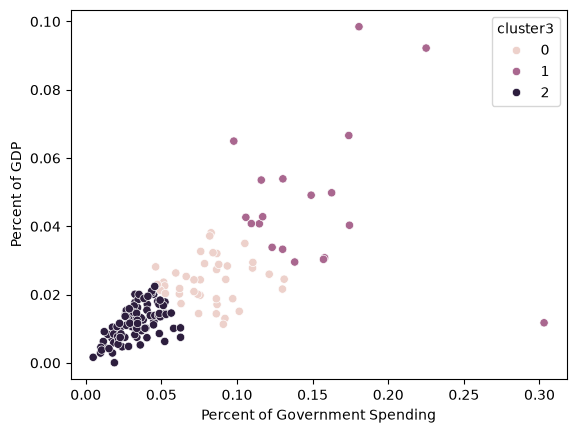

In [14]:
model3 = KMeans(n_clusters=3, n_init="auto", random_state=0).fit(X3)
df_2020["cluster3"] = model3.labels_

sns.scatterplot(data=df_2020, x="Percent of Government Spending", y="Percent of GDP", hue="cluster3")
plt.show()




In [12]:
print(df_2020.groupby("cluster3")[features3].describe())

         Percent of Government Spending                                \
                                  count      mean       std       min   
cluster3                                                                
0                                  40.0  0.081391  0.021601  0.046211   
1                                  19.0  0.150875  0.048785  0.097882   
2                                  89.0  0.033497  0.013242  0.004896   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster3                                                                    
0         0.065564  0.082430  0.092176  0.131184           40.0  0.023924   
1         0.116521  0.138143  0.168248  0.303027           19.0  0.047657   
2         0.023300  0.033620  0.043645  0.062685           89.0  0.011698   

                                                                      
               std       mi

In [ ]:
#When using all four variables, I chose k=4clusters. The algorithm still isolates the massive absolute spenders like the United States into their own tiny cluster 
#but it does a much better job of separating the rest of the world.
# Instead of puting 111 countries into a single low-spending group like in Part 2, 
#it uses the percentage variables to split those smaller countries based on their relative economic burden.


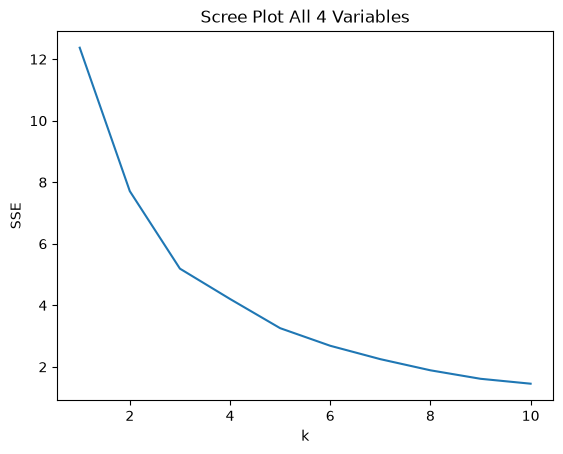

In [13]:

features4 = [
    "Spending (2020 USD)", "Spending per Capita", 
    "Percent of Government Spending", "Percent of GDP"
]
unscaled4 = df_2020.loc[:, features4]
mins4 = unscaled4.min()
ranges4 = unscaled4.max() - mins4
X4 = (unscaled4 - mins4) / ranges4


SSE4 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X4).inertia_ 
    for k in ks
]
sns.lineplot(x=ks, y=SSE4).set(title="Scree Plot All 4 Variables", xlabel="k", ylabel="SSE")
plt.show()




In [48]:
model4 = KMeans(n_clusters=4, n_init="auto", random_state=0).fit(X4)
df_2020["cluster4"] = model4.labels_


print(df_2020.groupby("cluster4")[features4].describe())

         Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster4                                                                  
0                       31.0    8786.086602   17901.909108   162.373364   
1                        2.0   35327.054356   41339.365456  6095.708713   
2                        4.0  204283.345885  382796.365368  6941.042345   
3                      111.0    7086.472777   26479.379918     8.622460   

                                                                    \
                   25%           50%            75%            max   
cluster4                                                             
0           467.787851   1404.787234    7739.166193   72937.064048   
1         20711.381534  35327.054356   49942.727178   64558.400000   
2          9219.189158  15897.570598  210961.727326  778397.200000   
3           130.010211    567.650747    3910.107493  2

In [ ]:
#Yes, the k-means algorithm found very useful patterns. Clustering by absolute dollars just grouped the wealthiest countries together, 
#while clustering by percentages showed the actual economic burden on smaller countries. 
#Using all four variables at once was the most useful because it gave the best of both worlds
# it captured the massive scale of the superpowers
# while still showing the real economic impact on every country.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** GPT-5.6 Sol.

### *Prompts used

Here is my code: [I paste all my code here]

I am a data science student. Review my code and suggest changes that would improve its correctness, readability, and efficiency. Explain each suggested change in beginner-friendly language and make sure it follows the methods taught in class. Do not change my code unnecessarily.

2. Code Revision Prompt

Using the feedback above, provide the full revised version of my code. Preserve my original approach and make only the changes that are necessary or beneficial. Keep the code at an appropriate level for a data science student, use methods covered in class, and include clear comments where helpful. Ensure the revised code answers the original question and explain the main changes you made.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Replace the repeated KMeans calculations with a loop over all five datasets.
2. Explain that increasing noise causes the clusters to overlap more.
3. Describe the scree plots using both the overall SSE and how clear the elbow is.
4. Explain that after the elbow, adding more clusters gives smaller improvements in SSE and may start fitting noise instead of meaningful groups.
5. Do not remove extreme countries such as the United States. Instead, make sure the clustering variables are numeric and use min-max normalization.
6. Explain that the Part 2 clusters are strongly affected by differences in country size and wealth. The United States forms its own cluster because its military spending is much higher than other countries.
7. Explain that Percent of Government Spending and Percent of GDP create more balanced clusters because they measure military spending relative to each country's resources instead of absolute dollars.
8. Explain that using all four variables combines absolute military spending with relative economic burden, giving a more complete picture than using either pair of variables alone.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | This produces the same SSE values but makes the code shorter and easier to read. The lecture uses `KMeans(...).fit(X).inertia_` to calculate SSE for each value of k. |
| 2 | Modify | Low noise creates more distinct clusters, while high noise causes more overlap between groups. |
| 3 | Modify | Higher noise generally increases SSE and makes the elbow less clear. This makes choosing the correct number of clusters less certain. |
| 4 | Modify | After the elbow, adding more clusters only slightly reduces SSE, so the extra clusters may be fitting noise instead of meaningful groups. |
| 5 | Modify | The United States is an extreme value, but it is real data and should not automatically be removed. The main cleaning steps are checking that the variables are numeric and normalizing them because they use different scales. |
| 6 | Accept | The spending-based clusters are strongly affected by country size and wealth. Most countries fall into a lower-spending cluster, while the United States forms its own cluster because its total military spending is much higher. |
| 7 | Accept | The percentage variables create more balanced clusters because they measure military spending relative to government spending and GDP instead of only using absolute dollar amounts. |
| 8 | Modify | Using all four variables combines total spending with relative military burden. The United States is no longer alone but remains in a small cluster, giving a more complete picture of military spending patterns. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [1]:
# Your Phase 2 solution to the problem goes here.
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

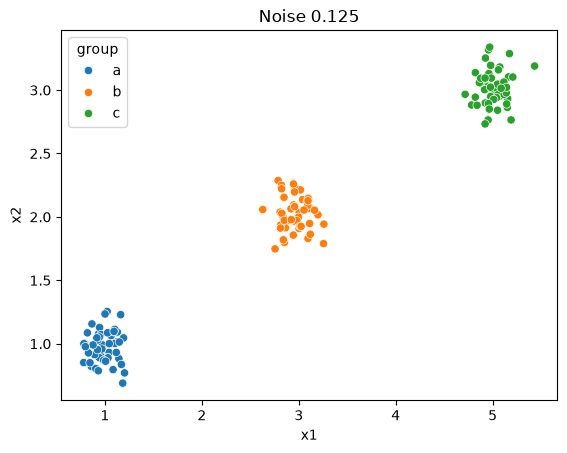

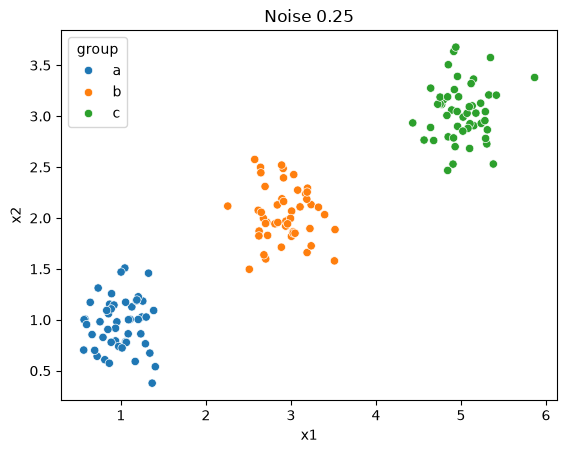

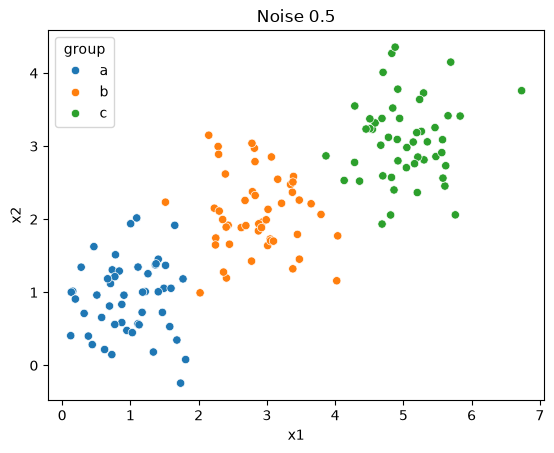

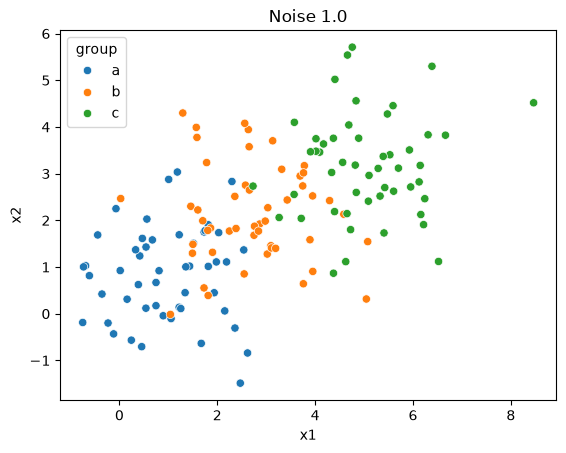

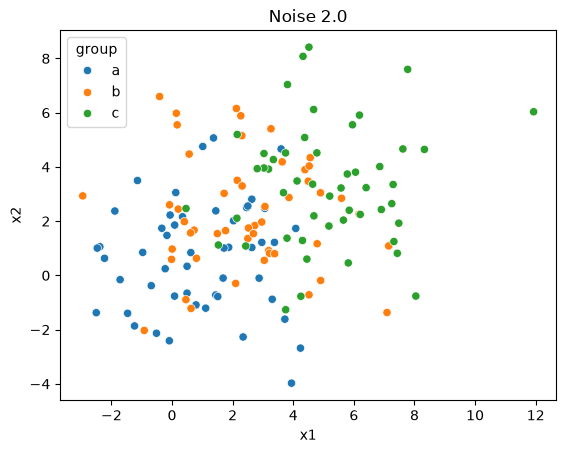

In [2]:
datasets = {
    "Noise 0.125": df0_125,
    "Noise 0.25": df0_25,
    "Noise 0.5": df0_5,
    "Noise 1.0": df1_0,
    "Noise 2.0": df2_0
}

for title, df in datasets.items():

    sns.scatterplot(
        data=df,
        x="x1",
        y="x2",
        hue="group"
    )

    plt.title(title)
    plt.show()


# ANSWER:
# As the noise increases, the clusters become more spread out
# and begin to overlap more.
#
# At noise = 0.125, the three clusters are very clear and tightly packed.
# Around noise = 0.5, the clusters begin to overlap.
# At noise = 1.0 and 2.0, the groups overlap much more and it becomes
# difficult to visually tell the clusters apart.
#
# Therefore, increasing noise makes the clusters less visually distinct.



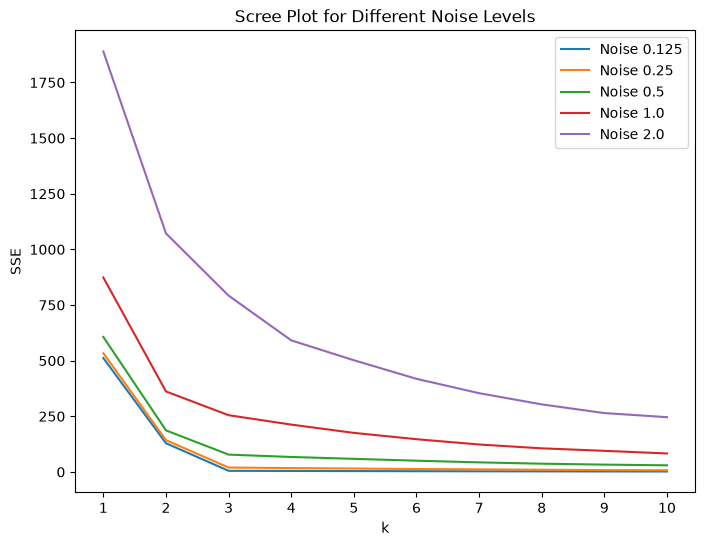

In [3]:
ks = np.arange(1, 11)

plt.figure(figsize=(8, 6))

for name, df in datasets.items():

    SSE = [
        KMeans(
            n_clusters=k,
            max_iter=300,
            n_init=10,
            random_state=0
        ).fit(df[["x1", "x2"]]).inertia_

        for k in ks
    ]

    sns.lineplot(
        x=ks,
        y=SSE,
        label=name
    )


plt.title("Scree Plot for Different Noise Levels")
plt.xlabel("k")
plt.ylabel("SSE")
plt.xticks(ks)
plt.legend()
plt.show()


# ANSWER:
# As noise increases, the overall SSE becomes larger because the points
# are more spread out from their cluster centers.
#
# At low noise levels, there is a clear elbow around k = 3.
# This makes it easy to choose 3 clusters.
#
# As the noise increases, the elbow becomes less obvious.
# At noise = 1.0 and especially 2.0, the SSE decreases more gradually,
# so it becomes harder to confidently choose the best value of k.
#
# Therefore, more noise makes choosing k from the scree plot more difficult.



In [ ]:
# ANSWER:
# The elbow shows where adding more clusters stops giving a large
# improvement in SSE.
#
# In the low-noise data, there are three real groups.
# Going from k = 1 to k = 2 and then k = 3 greatly decreases SSE
# because KMeans is separating those three groups.
#
# After k = 3, adding more clusters still decreases SSE,
# but the improvement is much smaller because the three main groups
# have already been identified.
#
# This creates an elbow around k = 3.
#
# When noise is high, the groups overlap more, so there is not a large
# change in SSE at k = 3. The curve becomes smoother and the elbow
# becomes harder to see.

In [2]:
# Q2 - K-Means Clustering Case Study

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler


# ============================================================
# PART 1: LOAD AND CLEAN THE DATA
# ============================================================

df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")

# Keep only observations from 2020
df2020 = df[df["Year"] == 2020].copy()

variables = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

# Make sure the clustering variables are numeric.
# This removes commas, dollar signs, and percent signs if they are present.
for col in variables:
    df2020[col] = (
        df2020[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.replace("$", "", regex=False)
        .str.replace("%", "", regex=False)
    )
    df2020[col] = pd.to_numeric(df2020[col], errors="coerce")

# Drop rows with missing values
df2020 = df2020.dropna().copy()

print("Number of countries:", len(df2020))
print("\nData types:")
print(df2020[variables].dtypes)


# ANSWER PART 1:
# The United States is an extreme observation, but it is real data and should
# not automatically be removed. The important additional cleaning step is
# making sure the clustering variables are numeric. The variables also need
# to be normalized because they are measured on very different scales.
#No observations should be removed solely for being extreme. 
#The variables were checked to ensure they are numeric; min-max normalization is then required
#before clustering because their scales differ.

Number of countries: 148

Data types:
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object


In [3]:
# ============================================================
# HELPER FUNCTIONS
# ============================================================

def normalize(data, columns):
    scaler = MinMaxScaler()
    return pd.DataFrame(
        scaler.fit_transform(data[columns]),
        columns=columns,
        index=data.index
    )


def scree_plot(X, title):
    sse = []

    for k in range(1, 11):
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )
        model.fit(X)
        sse.append(model.inertia_)

    plt.figure(figsize=(7, 5))
    plt.plot(range(1, 11), sse, marker="o")
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("SSE")
    plt.title(title)
    plt.xticks(range(1, 11))
    plt.show()

    return sse


def fit_clusters(X, k):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    return model.fit_predict(X)


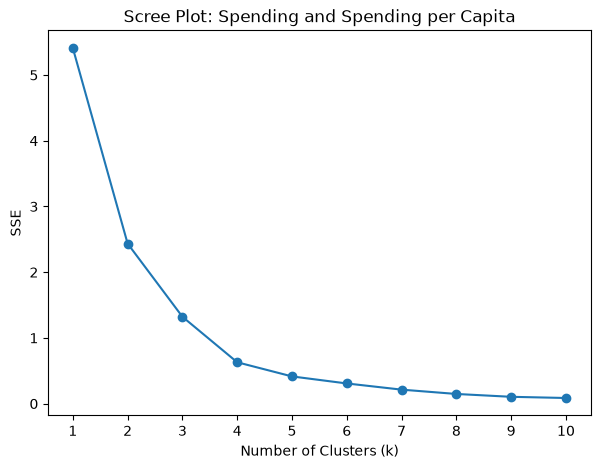

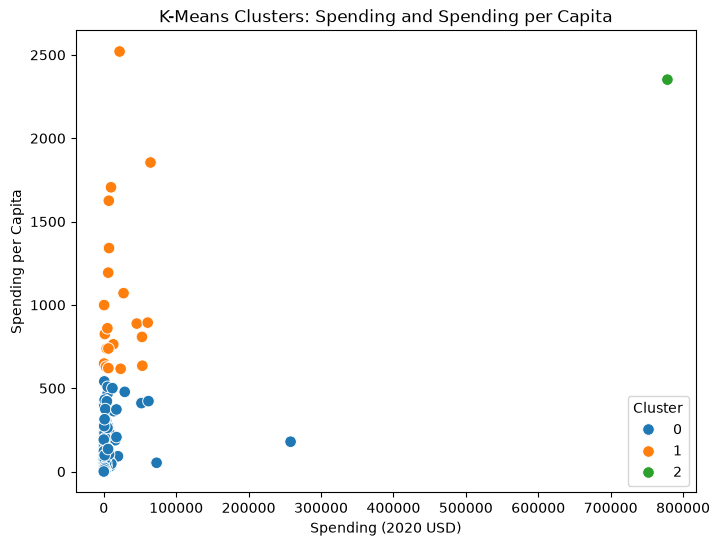


PART 2 DESCRIBE TABLE


Spending (2020 USD)                                              \
                            count           mean           std            min   
Cluster_Part2                                                                   
0                           126.0    5943.346303  24858.961064       8.622460   
1                            21.0   19975.991473  21749.736747     405.790494   
2                             1.0  778397.200000           NaN  778397.200000   

                                                                           \
                         25%            50%            75%            max   
Cluster_Part2                                                               
0                 162.761743     580.758315    3225.333414  257973.429834   
1                4980.428135    7269.880030   27300.894701   64558.400000   
2              778397.200000  778397.200000  778397.200000  778397.200000   

              Spending per Capita                                        \
                            count         mean         std          min   
Cluster_Part2                                                             
0                           126.0   122.034996  140.041183     0.580129   
1                            21.0  1046.433509  501.631845   616.854430   
2                             1.0  2351.631858         NaN  2351.631858   

                                                                   
                       25%          50%          75%          max  
Cluster_Part2                                                      
0                18.505805    58.809109   188.249364   541.154778  
1               737.690186   859.880548  1193.598730  2520.398541  
2              2351.631858  2351.631858  2351.631858  2351.631858


UNITED STATES - PART 2


,Country,Spending (2020 USD),Spending per Capita,Cluster_Part2
5540,United States of America,778397.2,2351.631858,2



PART 2 CLUSTER SIZES
Cluster_Part2
0    126
1     21
2      1
Name: count, dtype: int64


In [4]:
# ============================================================
# PART 2: SPENDING + SPENDING PER CAPITA
# ============================================================

part2_vars = [
    "Spending (2020 USD)",
    "Spending per Capita"
]

# Min-max normalization
X2 = normalize(df2020, part2_vars)

# Scree plot
sse2 = scree_plot(
    X2,
    "Scree Plot: Spending and Spending per Capita"
)

# The elbow is around k = 3
k2 = 3

df2020["Cluster_Part2"] = fit_clusters(X2, k2)

# Scatter plot
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df2020,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="Cluster_Part2",
    palette="tab10",
    s=70
)

plt.title("K-Means Clusters: Spending and Spending per Capita")
plt.xlabel("Spending (2020 USD)")
plt.ylabel("Spending per Capita")
plt.legend(title="Cluster")
plt.show()

# Describe table conditional on cluster
print("\nPART 2 DESCRIBE TABLE")
display(
    df2020.groupby("Cluster_Part2")[part2_vars].describe()
)

# Locate the United States
print("\nUNITED STATES - PART 2")
display(
    df2020[
        df2020["Country"].str.contains(
            "United States",
            case=False,
            na=False
        )
    ][
        [
            "Country",
            "Spending (2020 USD)",
            "Spending per Capita",
            "Cluster_Part2"
        ]
    ]
)

print("\nPART 2 CLUSTER SIZES")
print(df2020["Cluster_Part2"].value_counts().sort_index())


# ANSWER PART 2:
# The clusters are very uneven. Most countries are grouped into a lower-spending
# cluster. The results are strongly influenced by differences in country size
# and wealth. The United States is separated because its total military spending
# is much larger than the other countries.



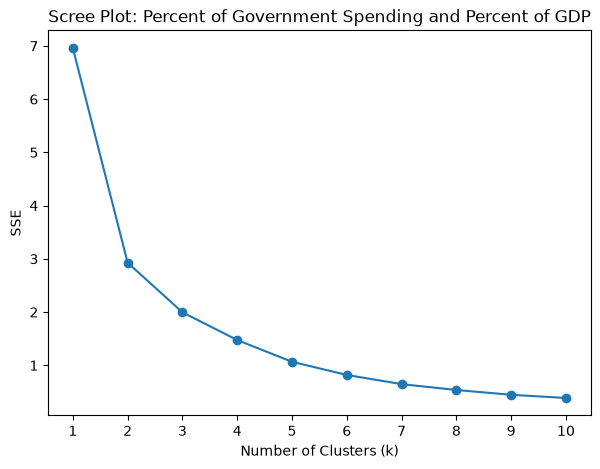

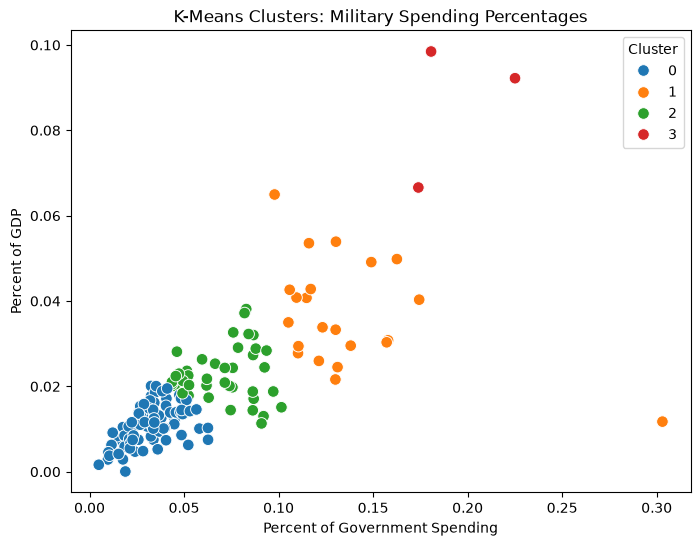


PART 3 DESCRIBE TABLE


Percent of Government Spending                                \
                                       count      mean       std       min   
Cluster_Part3                                                                
0                                       83.0  0.032552  0.013192  0.004896   
1                                       22.0  0.136158  0.042661  0.097882   
2                                       40.0  0.070664  0.017720  0.043592   
3                                        3.0  0.193209  0.027779  0.173924   

                                                      Percent of GDP  \
                    25%       50%       75%       max          count   
Cluster_Part3                                                          
0              0.022839  0.032524  0.040564  0.062685           83.0   
1              0.111561  0.126638  0.146304  0.303027           22.0   
2              0.052339  0.074328  0.086389  0.101501           40.0   
3              0.177289  0.180654  0.202852  0.225050            3.0   

                                                                           \
                   mean       std       min       25%       50%       75%   
Cluster_Part3                                                               
0              0.011094  0.004627  0.000054  0.007500  0.011015  0.014322   
1              0.036932  0.012381  0.011742  0.029458  0.034419  0.042766   
2              0.022824  0.006231  0.011317  0.018798  0.021527  0.026590   
3              0.085760  0.016886  0.066600  0.079405  0.092211  0.095341   

                         
                    max  
Cluster_Part3            
0              0.020095  
1              0.064961  
2              0.038118  
3              0.098470


PART 3 CLUSTER SIZES
Cluster_Part3
0    83
1    22
2    40
3     3
Name: count, dtype: int64

UNITED STATES - PART 3


,Country,Percent of Government Spending,Percent of GDP,Cluster_Part3
5540,United States of America,0.081976,0.037179,2


In [5]:
# ============================================================
# PART 3: PERCENT GOVERNMENT SPENDING + PERCENT GDP
# ============================================================

part3_vars = [
    "Percent of Government Spending",
    "Percent of GDP"
]

# Min-max normalization
X3 = normalize(df2020, part3_vars)

# Scree plot
sse3 = scree_plot(
    X3,
    "Scree Plot: Percent of Government Spending and Percent of GDP"
)

# The elbow is around k = 4
k3 = 4

df2020["Cluster_Part3"] = fit_clusters(X3, k3)

# Scatter plot
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df2020,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="Cluster_Part3",
    palette="tab10",
    s=70
)

plt.title("K-Means Clusters: Military Spending Percentages")
plt.xlabel("Percent of Government Spending")
plt.ylabel("Percent of GDP")
plt.legend(title="Cluster")
plt.show()

# Describe table conditional on cluster
print("\nPART 3 DESCRIBE TABLE")
display(
    df2020.groupby("Cluster_Part3")[part3_vars].describe()
)

print("\nPART 3 CLUSTER SIZES")
print(df2020["Cluster_Part3"].value_counts().sort_index())

# United States in Part 3
print("\nUNITED STATES - PART 3")
display(
    df2020[
        df2020["Country"].str.contains(
            "United States",
            case=False,
            na=False
        )
    ][
        [
            "Country",
            "Percent of Government Spending",
            "Percent of GDP",
            "Cluster_Part3"
        ]
    ]
)


# ANSWER PART 3:
# These clusters are more balanced than the clusters in Part 2. Percent of
# Government Spending and Percent of GDP measure military spending relative
# to each country's resources rather than simply comparing dollar amounts.
# This reduces the effect of differences in country size and wealth.



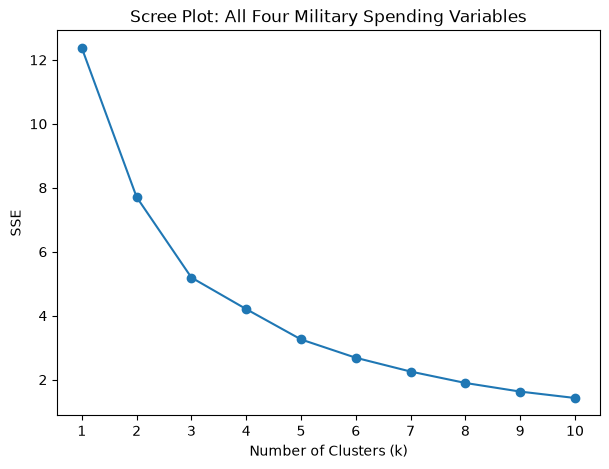


PART 4 DESCRIBE TABLE


Spending (2020 USD)                                             \
                            count           mean            std          min   
Cluster_Part4                                                                  
0                            31.0    8786.086602   17901.909108   162.373364   
1                             6.0  147964.582042  309635.189564  6095.708713   
2                           111.0    7086.472777   26479.379918     8.622460   

                                                                       \
                       25%           50%           75%            max   
Cluster_Part4                                                           
0               467.787851   1404.787234   7739.166193   72937.064048   
1              7700.424616  15897.570598  53872.942442  778397.200000   
2               130.010211    567.650747   3910.107493  257973.429834   

              Spending per Capita               ...  \
                            count         mean  ...   
Cluster_Part4                                   ...   
0                            31.0   212.689100  ...   
1                             6.0  1875.150751  ...   
2                           111.0   196.926833  ...   

              Percent of Government Spending           Percent of GDP  \
                                         75%       max          count   
Cluster_Part4                                                           
0                                   0.134663  0.303027           31.0   
1                                   0.164503  0.225050            6.0   
2                                   0.050505  0.092044          111.0   

                                                                           \
                   mean       std       min       25%       50%       75%   
Cluster_Part4                                                               
0              0.033492  0.011449  0.011742  0.027560  0.032024  0.040531   
1              0.062634  0.028275  0.029429  0.041272  0.059257  0.085398   
2              0.013419  0.005996  0.000054  0.008873  0.013589  0.017769   

                         
                    max  
Cluster_Part4            
0              0.066600  
1              0.098470  
2              0.028132  

[3 rows x 32 columns]


PART 4 CLUSTER SIZES
Cluster_Part4
0     31
1      6
2    111
Name: count, dtype: int64

UNITED STATES - PART 4


,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP,Cluster_Part4
5540,United States of America,778397.2,2351.631858,0.081976,0.037179,1


In [6]:
# ============================================================
# PART 4: ALL FOUR VARIABLES
# ============================================================

part4_vars = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

# Normalize all four variables together
X4 = normalize(df2020, part4_vars)

# Scree plot
sse4 = scree_plot(
    X4,
    "Scree Plot: All Four Military Spending Variables"
)

# The elbow is around k = 3
k4 = 3

df2020["Cluster_Part4"] = fit_clusters(X4, k4)

# Describe table
print("\nPART 4 DESCRIBE TABLE")
display(
    df2020.groupby("Cluster_Part4")[part4_vars].describe()
)

print("\nPART 4 CLUSTER SIZES")
print(df2020["Cluster_Part4"].value_counts().sort_index())

# United States in Part 4
print("\nUNITED STATES - PART 4")
display(
    df2020[
        df2020["Country"].str.contains(
            "United States",
            case=False,
            na=False
        )
    ][
        [
            "Country",
            "Spending (2020 USD)",
            "Spending per Capita",
            "Percent of Government Spending",
            "Percent of GDP",
            "Cluster_Part4"
        ]
    ]
)


# ANSWER PART 4:
# Using all four variables combines absolute military spending with spending
# relative to a country's resources. Cluster 2 contains most countries (111),
# Cluster 0 contains 31 countries, and Cluster 1 is a small group of 6 countries.
# The United States is in Cluster 1, so it is no longer in its own cluster as
# it was in Part 2. Cluster 1 has much higher average total spending and spending
# per capita than the other clusters. Overall, using all four variables gives
# a broader picture of military spending than using either pair of variables alone.


In [18]:

comparison = df2020[
    [
        "Country",
        "Cluster_Part2",
        "Cluster_Part3",
        "Cluster_Part4"
    ]
].sort_values("Country")

print("\nCLUSTER MEMBERSHIP COMPARISON")
display(comparison)


# ANSWER PART 5:
# Yes, K-means found useful patterns in military spending. The results show that
# cluster membership changes depending on which variables are used. In Part 2,
# the United States formed its own cluster because of its very high total spending.
# In Part 4, the United States joined a small cluster of 6 countries when both
# absolute spending and percentage measures were included. This shows that using
# all four variables gives a more complete view of differences between countries.


CLUSTER MEMBERSHIP COMPARISON


,Country,Cluster_Part2,Cluster_Part3,Cluster_Part4
32,Afghanistan,0,1,2
66,Albania,0,1,2
100,Algeria,0,2,0
134,Angola,0,1,2
168,Argentina,0,1,2
...,...,...,...,...
5506,United Kingdom,1,1,2
5540,United States of America,2,0,1
5574,Uruguay,0,1,2
5846,Zambia,0,1,2


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements were making the code easier to understand. Also it helps check that all clustering variables were numeric, it also used max-min normalization before K-means, and adding clearer comments to explain my answers. The AI also helped me make better comparisons between Parts 2, 3, and 4, especially when looking at the United States. One problem was that the AI initially made the code more complicated by adding extra functions and plots that were not needed. It also assumed that k = 3 was the best choice before checking the scree plots (however they cant see the plot which makes sense) . To verify the final code, I checked that 148 countries remained after cleaning and also made sure the normalized values were on the same scale. I also compared cluster sizes and describe tables. I also checked which cluster the United States belonged to in each section. One limitation is that choosing the elbow point can be subjective when the scree plot does not show a clear bend.